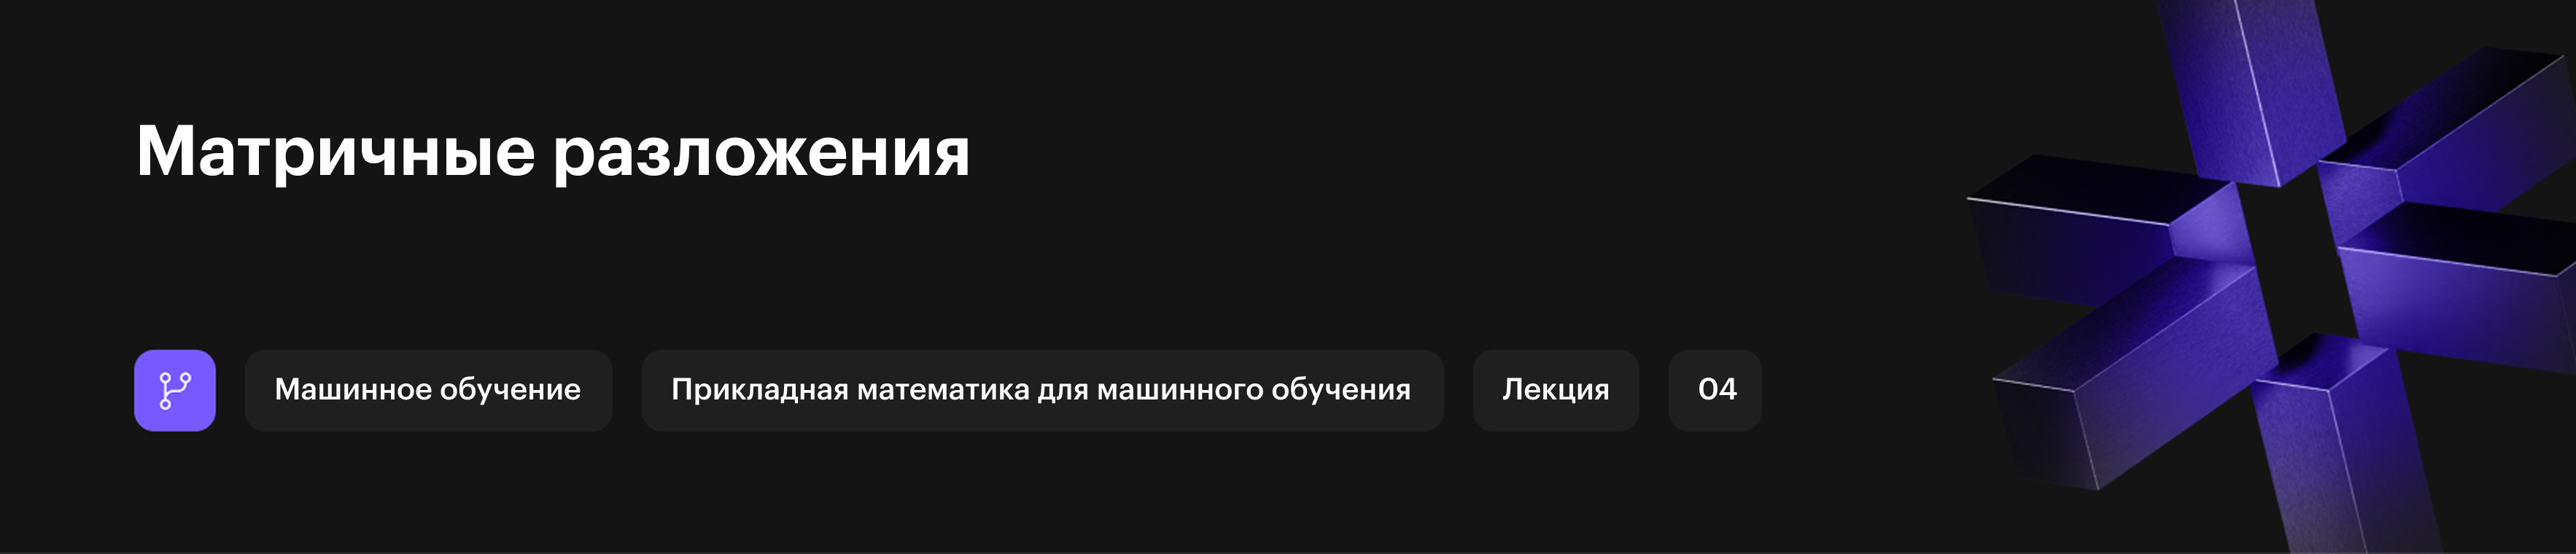

# Неделя 4. Матричные разложения

Рассмотрим модельную задачу снижения размерности с помощью PCA.

In [ ]:
import numpy as np
from sklearn.decomposition import PCA

Построим SVD-разложение некоторой матрицы.

In [ ]:
X  = np.array([
    [1, 2, 3, 4],
    [2, 4, 2, 5],
    [3, 6, 1, 3],
    [4, 8, 3, 2],
    [5, 10, 2, 1],
    [6, 12, 1, 8],
])

In [ ]:
U, S, Vt = np.linalg.svd(X, full_matrices=True)

In [ ]:
U

array([[-0.17590132, -0.50052851,  0.60393182,  0.54586654, -0.21984627,
         0.08656575],
       [-0.27071737, -0.47375543,  0.17701652, -0.42177   ,  0.69508912,
        -0.09946971],
       [-0.314288  ,  0.00689827, -0.09270529,  0.08343825, -0.17576751,
        -0.92451341],
       [-0.39732031,  0.28119271,  0.47620552, -0.5860683 , -0.42324124,
         0.11698859],
       [-0.45797275,  0.61055288,  0.15408588,  0.41323003,  0.46273933,
         0.09411131],
       [-0.65527965, -0.2704353 , -0.58721639,  0.05424696, -0.21062685,
         0.32456716]])

In [ ]:
S

array([2.35764507e+01, 5.94142393e+00, 3.29400280e+00, 5.30131565e-16])

In [ ]:
Vt

array([[-4.01715383e-01, -8.03430767e-01, -1.75879434e-01,
        -4.02728418e-01],
       [ 1.89782604e-01,  3.79565208e-01, -1.09056270e-01,
        -8.98899074e-01],
       [-5.10618649e-02, -1.02123730e-01,  9.78352265e-01,
        -1.72598595e-01],
       [ 8.94427191e-01, -4.47213595e-01,  4.16333634e-17,
         1.38777878e-16]])

In [ ]:
S_diag = np.zeros(X.shape)
for i, v in enumerate(S):
  S_diag[i,i] = v

In [ ]:
S_diag

array([[2.35764507e+01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 5.94142393e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 3.29400280e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 5.30131565e-16],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00]])

Проверим на корректность.

In [ ]:
U @ U.T

array([[ 1.00000000e+00,  1.20448712e-17,  1.23664800e-16,
        -1.87601584e-17, -2.55379621e-17,  1.87470673e-17],
       [ 1.20448712e-17,  1.00000000e+00,  8.77519393e-17,
         1.90698952e-16,  4.09328564e-17,  8.81255312e-17],
       [ 1.23664800e-16,  8.77519393e-17,  1.00000000e+00,
         1.64443886e-16,  1.08234646e-16,  1.07886697e-18],
       [-1.87601584e-17,  1.90698952e-16,  1.64443886e-16,
         1.00000000e+00, -2.29697537e-17,  1.20815878e-16],
       [-2.55379621e-17,  4.09328564e-17,  1.08234646e-16,
        -2.29697537e-17,  1.00000000e+00,  1.15026941e-16],
       [ 1.87470673e-17,  8.81255312e-17,  1.07886697e-18,
         1.20815878e-16,  1.15026941e-16,  1.00000000e+00]])

In [ ]:
Vt @ Vt.T

array([[ 1.00000000e+00,  1.29201871e-16, -9.90491415e-17,
        -8.93157162e-17],
       [ 1.29201871e-16,  1.00000000e+00, -4.30901689e-16,
        -2.10385354e-16],
       [-9.90491415e-17, -4.30901689e-16,  1.00000000e+00,
         7.59802183e-17],
       [-8.93157162e-17, -2.10385354e-16,  7.59802183e-17,
         1.00000000e+00]])

In [ ]:
U @ S_diag @ Vt

array([[ 1.,  2.,  3.,  4.],
       [ 2.,  4.,  2.,  5.],
       [ 3.,  6.,  1.,  3.],
       [ 4.,  8.,  3.,  2.],
       [ 5., 10.,  2.,  1.],
       [ 6., 12.,  1.,  8.]])

Применим встроенный PCA.

PCA позволяет найти направления (главные компоненты) в данных, где находится основная часть их вариативности. Первая главная компонента — это направление, вдоль которого разброс данных максимален.

In [ ]:
pca = PCA(n_components=4)

In [ ]:
pca.fit(X)

PCA(n_components=4)

In [ ]:
# Векторы, на которые нужно строить проекции
pca.components_

array([[ 4.39993654e-01,  8.79987308e-01, -1.10970152e-01,
         1.40404939e-01],
       [-6.92112929e-02, -1.38422586e-01, -1.33576934e-01,
         9.78880068e-01],
       [ 4.01918052e-02,  8.03836104e-02,  9.84805985e-01,
         1.48594299e-01],
       [ 8.94427191e-01, -4.47213595e-01,  1.04083409e-16,
         3.46944695e-17]])

In [ ]:
# Сингулярные значения векторов выше
pca.singular_values_

array([9.46708549e+00, 5.50257195e+00, 1.55863003e+00, 4.38770145e-16])

Совпадают ли PCA и SVD-разложения? Что забыли сделать перед применением SVD?

Изначально SVD-разложение выполнялось для нецентрированной матрицы, оно работает на любой матрице. PCA же требует центрирования данных: он измеряет разброс относительно среднего. Если применить SVD к центрированным данным, он даст ровно те же главные компоненты и сингулярные числа, что и PCA. `sklearn` внутри PCA делает именно это: центрирует данные, затем применяет SVD.



In [ ]:
# Среднее по столбцам
X.mean(axis=0)

array([3.5       , 7.        , 2.        , 3.83333333])

In [ ]:
X_centred = X - X.mean(axis=0)

In [ ]:
X_centred

array([[-2.5       , -5.        ,  1.        ,  0.16666667],
       [-1.5       , -3.        ,  0.        ,  1.16666667],
       [-0.5       , -1.        , -1.        , -0.83333333],
       [ 0.5       ,  1.        ,  1.        , -1.83333333],
       [ 1.5       ,  3.        ,  0.        , -2.83333333],
       [ 2.5       ,  5.        , -1.        ,  4.16666667]])

In [ ]:
U, S, Vt = np.linalg.svd(X_centred, full_matrices=True)

In [ ]:
S

array([9.46708549e+00, 5.50257195e+00, 1.55863003e+00, 4.38770145e-16])

In [ ]:
Vt[:]

array([[ 4.39993654e-01,  8.79987308e-01, -1.10970152e-01,
         1.40404939e-01],
       [ 6.92112929e-02,  1.38422586e-01,  1.33576934e-01,
        -9.78880068e-01],
       [ 4.01918052e-02,  8.03836104e-02,  9.84805985e-01,
         1.48594299e-01],
       [-8.94427191e-01,  4.47213595e-01, -1.04083409e-16,
        -3.46944695e-17]])

Совпало!

Вычислим долю дисперсии, которую удаётся сохранить, если оставить только первые две главные компоненты. И доли дисперсии, которые объясняют каждые соответствующие компоненты.

In [ ]:
k = 2

variance_ratio = np.sum(S[:k]**2) / np.sum(S**2)
print(f"Сохранено {variance_ratio:.1%} дисперсии")

pca_ratios = pca.explained_variance_ratio_
pca_percent = [f'{r:.1%}' for r in pca_ratios]
print("PCA explained_variance_ratio_ (в %):", pca_percent)


Сохранено 98.0% дисперсии
PCA explained_variance_ratio_ (в %): ['73.3%', '24.8%', '2.0%', '0.0%']


In [ ]:
Z = X_centred @ Vt[:k].T
Z

array([[-5.58749001, -0.89471091],
       [-3.13614664, -1.66111144],
       [-1.1060181 ,  0.50912822],
       [ 0.73160493,  2.10121862],
       [ 2.90213841,  3.29257822],
       [ 6.19591141, -3.34710272]])

In [ ]:
S_diag = np.zeros(X.shape)
for i, v in enumerate(S):
  S_diag[i,i] = v
U[:,:k] @ S_diag[:k,:k]


array([[-5.58749001, -0.89471091],
       [-3.13614664, -1.66111144],
       [-1.1060181 ,  0.50912822],
       [ 0.73160493,  2.10121862],
       [ 2.90213841,  3.29257822],
       [ 6.19591141, -3.34710272]])

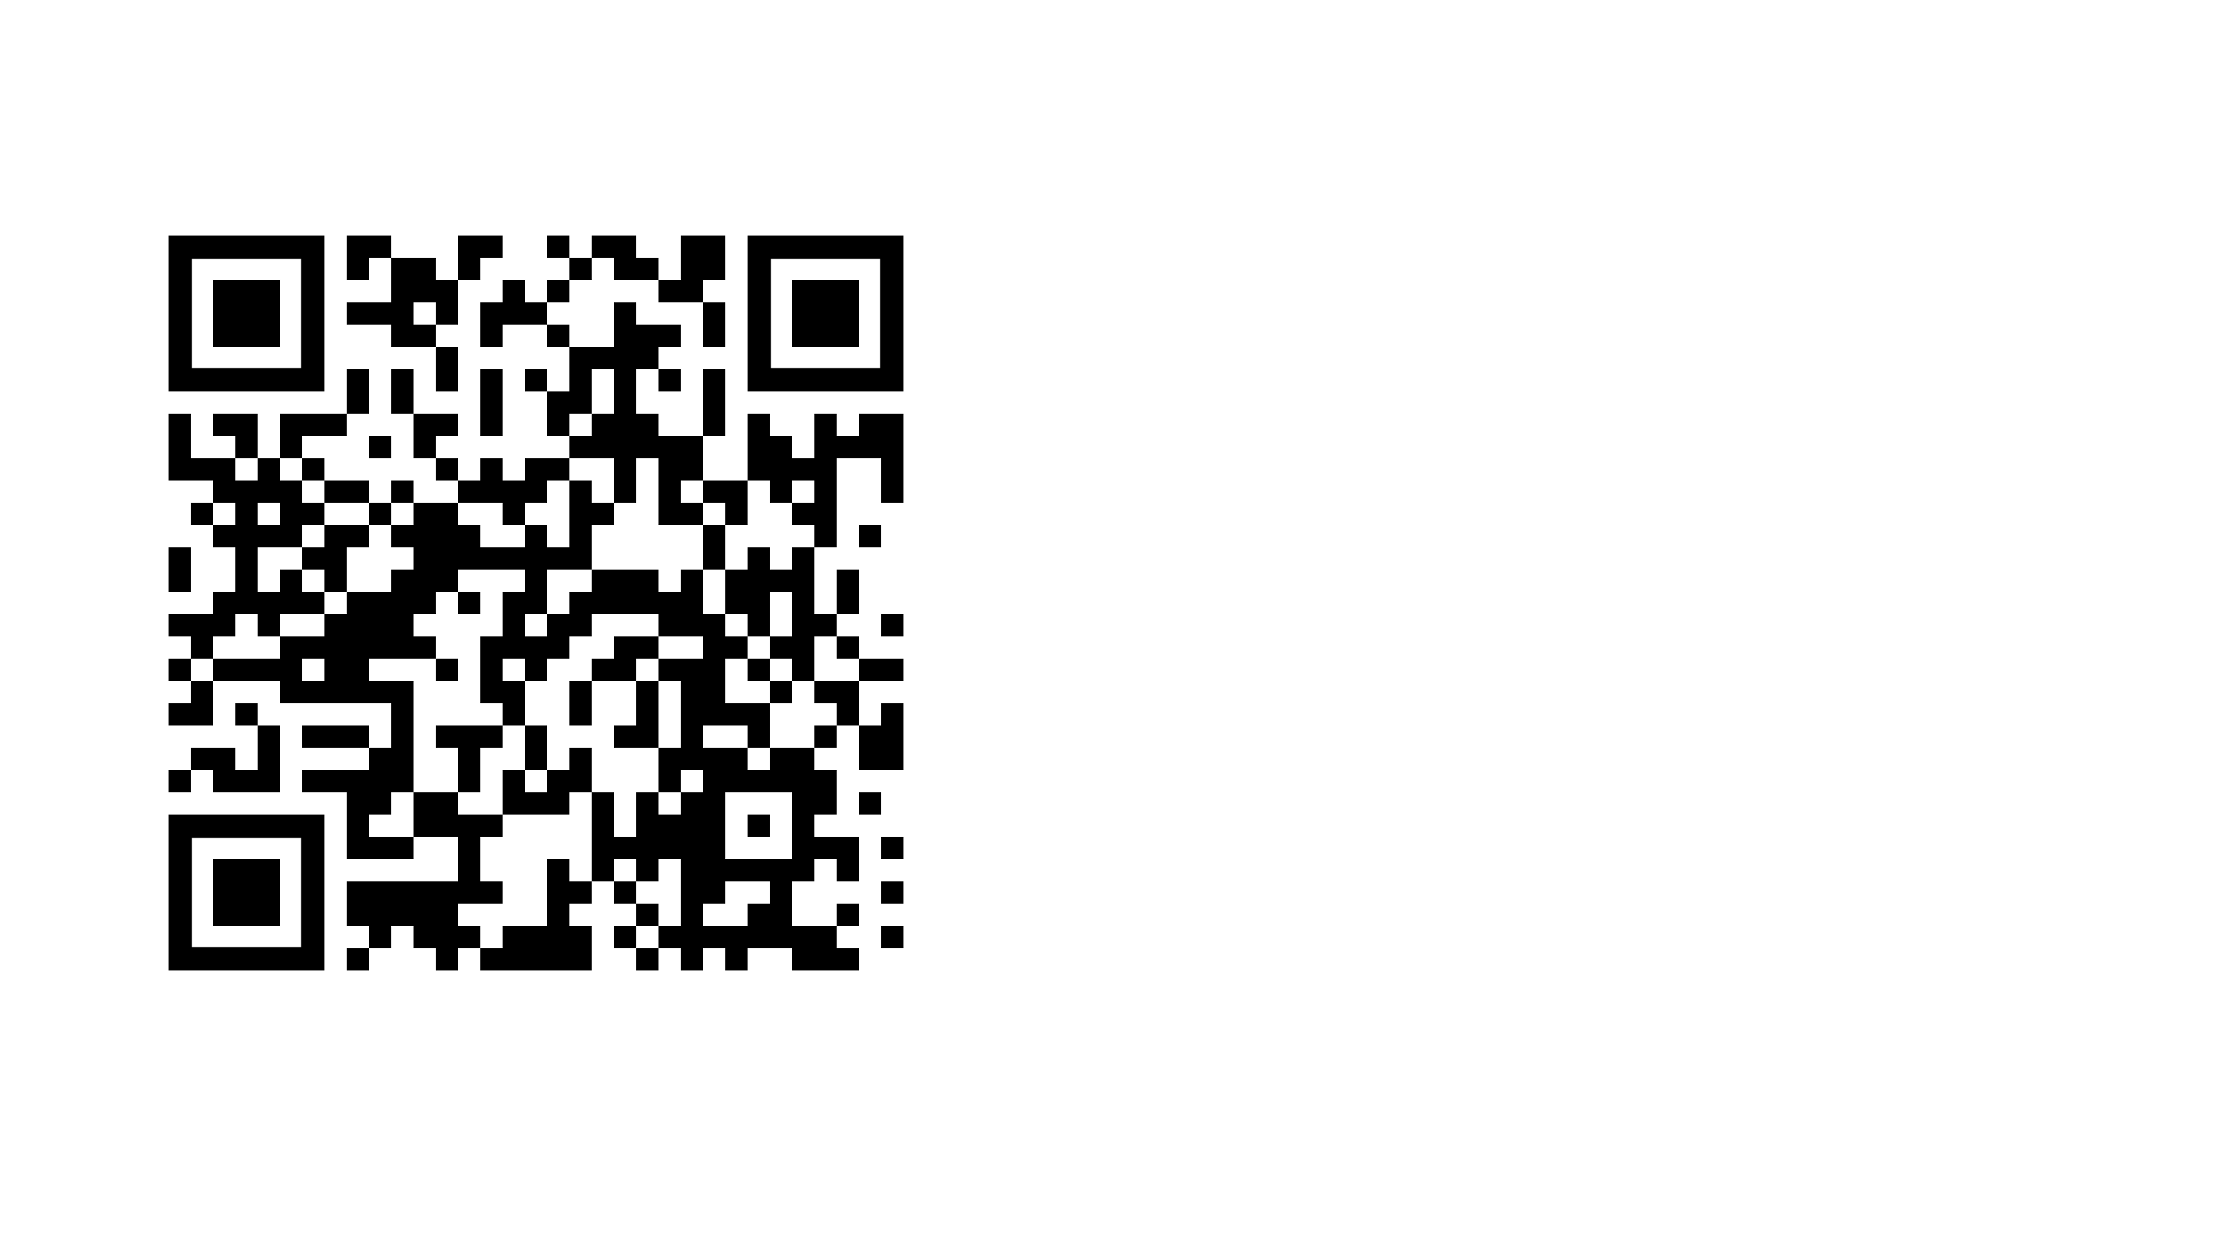